<a href="https://colab.research.google.com/github/leonardo2004/Calculo-Numerico/blob/main/Sistemas%20lineares%202/Sistemas_linerares_em_c%C3%A1lculo_num%C3%A9rico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Item 5 & 6: Implementação do Método de Gauss-Seidel e Tabela de Iterações

O código abaixo implementa o método de Gauss-Seidel, calcula as iterações e gera automaticamente a tabela formatada em Markdown com os resultados de cada passo.

In [3]:
# -*- coding: utf-8 -*-
"""Gauss-Seidel para o sistema da lista (Itens 5, 6 e 7)

10x -  y + 2z =   6
-x + 11y -  z =  22
2x -  y + 10z = -10
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sistema linear Ax = b (corrigido: o mesmo da lista de exercícios)
A = np.array([
    [10.0, -1.0, 2.0],
    [-1.0, 11.0, -1.0],
    [2.0, -1.0, 10.0]
], dtype=float)

b = np.array([6.0, 22.0, -10.0], dtype=float)

x = np.zeros(3, dtype=float)  # x^(0) = (0, 0, 0)
tol = 1e-5
max_iter = 100

history = [{'k': 0, 'x': x[0], 'y': x[1], 'z': x[2], 'error': None}]

for k in range(1, max_iter + 1):
    x_old = x.copy()

    # Gauss-Seidel: usa imediatamente os valores já atualizados
    x[0] = (b[0] - A[0, 1] * x[1] - A[0, 2] * x[2]) / A[0, 0]
    x[1] = (b[1] - A[1, 0] * x[0] - A[1, 2] * x[2]) / A[1, 1]
    x[2] = (b[2] - A[2, 0] * x[0] - A[2, 1] * x[1]) / A[2, 2]

    error = np.max(np.abs(x - x_old))  # norma do infinito

    history.append({'k': k, 'x': x[0], 'y': x[1], 'z': x[2], 'error': error})

    if error < tol:
        break

df_history = pd.DataFrame(history)

print(f"Método convergiu em {k} iterações.")
print(f"Solução aproximada final: x = {x[0]:.6f}, y = {x[1]:.6f}, z = {x[2]:.6f}\n")

# Tabela do Item 6 (k >= 1)
table_df = df_history[df_history['k'] >= 1].copy()
table_df.columns = ['k', 'x^(k)', 'y^(k)', 'z^(k)', '||x^(k) - x^(k-1)||_inf']
print(table_df.to_string(index=False))


Método convergiu em 6 iterações.
Solução aproximada final: x = 1.000000, y = 2.000000, z = -1.000000

 k    x^(k)    y^(k)     z^(k)  ||x^(k) - x^(k-1)||_inf
 1 0.600000 2.054545 -0.914545                 2.054545
 2 0.988364 2.006711 -0.997002                 0.388364
 3 1.000071 2.000279 -0.999986                 0.011708
 4 1.000025 2.000004 -1.000005                 0.000276
 5 1.000001 2.000000 -1.000000                 0.000024
 6 1.000000 2.000000 -1.000000                 0.000001


### Item 7: Geração de Gráficos de Convergência

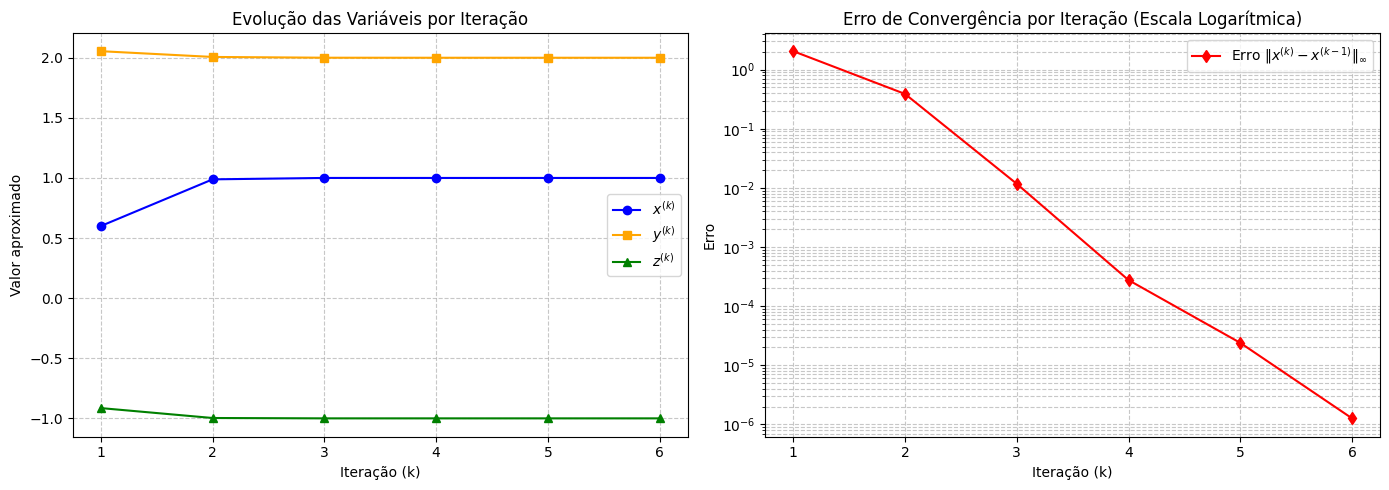

In [4]:
# ---------------- Item 7: gráficos ----------------
ks = [h['k'] for h in history if h['k'] >= 1]
xs = [h['x'] for h in history if h['k'] >= 1]
ys = [h['y'] for h in history if h['k'] >= 1]
zs = [h['z'] for h in history if h['k'] >= 1]
errors = [h['error'] for h in history if h['k'] >= 1]

plt.figure(figsize=(14, 5))

# (a) x, y, z em função de k
plt.subplot(1, 2, 1)
plt.plot(ks, xs, marker='o', color='blue', label='$x^{(k)}$')
plt.plot(ks, ys, marker='s', color='orange', label='$y^{(k)}$')
plt.plot(ks, zs, marker='^', color='green', label='$z^{(k)}$')
plt.title('Evolução das Variáveis por Iteração')
plt.xlabel('Iteração (k)')
plt.ylabel('Valor aproximado')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# (b) erro em escala logarítmica
plt.subplot(1, 2, 2)
plt.plot(ks, errors, marker='d', color='red',
         label=r'Erro $\|x^{(k)} - x^{(k-1)}\|_{\infty}$')
plt.yscale('log')
plt.title('Erro de Convergência por Iteração (Escala Logarítmica)')
plt.xlabel('Iteração (k)')
plt.ylabel('Erro')
plt.grid(True, which="both", linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.savefig('graficos_gauss_seidel.png', dpi=150)
plt.show()
